# Figure 2

Redraws every data panel of Figure 2 from the source data workbook `Figure_2.xlsx`.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib import font_manager

SOURCE = Path("..") / "Source data"                     # relative to this notebook's folder
BOOK = SOURCE / "Figure_2.xlsx"

FONT = "Calibri" if any(f.name == "Calibri" for f in font_manager.fontManager.ttflist) else "Carlito"
BASE, LETTER = 7.5, 10.5                                        # all text 7.5 pt; panel letters 10.5 pt bold
MM = 1 / 25.4
WIDTH = 180 * MM                                                # width of the published figure (in)
INK, INK3, GRIDC, NAVY = "#0b0b0b", "#76756f", "#eeeeec", "#22314a"
COL = {"local": "#2f6db5", "inbound": "#1a9e6f", "outbound": "#e86a33"}
TEAL, CORAL, GREY, LAND, EDGE = "#1795a3", "#d9644f", "#c7c6c1", "#f4f3f0", "#ffffff"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": [FONT], "mathtext.fontset": "custom",
    "mathtext.rm": FONT, "mathtext.it": f"{FONT}:italic", "mathtext.bf": f"{FONT}:bold",
    "mathtext.cal": FONT, "mathtext.sf": FONT, "mathtext.tt": FONT,
    "font.size": BASE, "axes.labelsize": BASE, "xtick.labelsize": BASE, "ytick.labelsize": BASE,
    "legend.fontsize": BASE, "axes.titlesize": BASE, "legend.title_fontsize": BASE, "legend.labelcolor": INK,
    "text.color": INK, "axes.edgecolor": INK3, "axes.linewidth": 0.5, "xtick.color": INK3, "ytick.color": INK3,
    "xtick.labelcolor": INK, "ytick.labelcolor": INK, "axes.labelcolor": INK,
    "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2, "ytick.major.size": 2,
    "xtick.major.pad": 1.5, "ytick.major.pad": 1.5, "axes.labelpad": 2,
    "legend.frameon": False, "axes.unicode_minus": True,
    "figure.dpi": 300, "figure.facecolor": "white", "figure.edgecolor": "white", "savefig.facecolor": "white"})
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}


def panel_figure(x0, y0, w, h):
    """One panel as a standalone figure; positions are inches from the lower-left corner of the published figure."""
    fig = plt.figure(figsize=(w, h))

    def ax_in(x, y, ww, hh, **kw):
        return fig.add_axes([(x - x0) / w, (y - y0) / h, ww / w, hh / h], **kw)

    def letter(x, y, s):
        fig.text((x - x0) / w, (y - y0) / h, s, fontsize=LETTER, fontweight="bold", color=INK, va="top", ha="left")

    def T(x, y, s, **kw):
        kw.setdefault("fontsize", BASE)
        kw.setdefault("color", INK)
        return fig.text((x - x0) / w, (y - y0) / h, s, **kw)

    return fig, ax_in, letter, T


def overlay(ax_in, x0, y0, w, h):
    """Transparent axes covering the panel, with data coordinates in inches of the published figure."""
    ov = ax_in(x0, y0, w, h)
    ov.set_xlim(x0, x0 + w)
    ov.set_ylim(y0, y0 + h)
    ov.axis("off")
    ov.patch.set_alpha(0)
    return ov


def clean(ax, grid="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if grid:
        ax.grid(axis=grid, color=GRIDC, lw=0.5)
        ax.set_axisbelow(True)


def nfmt(v, nd=1):
    return f"{v:.{nd}f}".replace("-", "\u2212")


def mfmt(v, nd=1):
    return f"{v:+.{nd}f}".replace("-", "\u2212")


def pfmt(p):
    return r"$P$ < 0.001" if p < 0.001 else rf"$P$ = {p:.3f}" if p < 0.01 else rf"$P$ = {p:.2f}"

from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory

H = 4.26                                                        # height of the published figure (in)
OCHRE = "#c98f1f"
PROD = {"ERA5-EF": ("ERA5-Land", NAVY), "CPC-EF": ("CPC gauge", OCHRE)}
DEMAND = COL["inbound"]                                         # partner demand weight = inbound spending
REF = dict(color=INK, lw=0.6, ls=(0, (3, 2)))                   # the ~450 km reference line
DIST_TICKS = [100, 200, 500, 1000, 2000]
LET = 0.14
AT1, R1H = H - 0.17, 1.90                                       # row 1: axes top and height
AB1 = AT1 - R1H
R2H = 1.30
AT2 = AB1 - 0.54
AB2 = AT2 - R2H


def dist_axis(ax_, labels=True):
    ax_.set_xscale("log")
    ax_.set_xlim(50, 3500)
    ax_.set_xticks(DIST_TICKS)
    ax_.set_xticklabels(["100", "200", "500", "1,000", "2,000"] if labels else [])
    ax_.minorticks_off()


def ci_txt(est, lo, hi, nd=1, scale=100, pct=False):
    f = lambda v: f"{scale * v:.{nd}f}".replace("-", "\u2212")
    return f"{f(est)}{'%' if pct else ''} [{f(lo)}, {f(hi)}]"

**Panel a**: chance of same-day extreme rain against distance (upper) and cumulative share of partner demand within distance (lower).

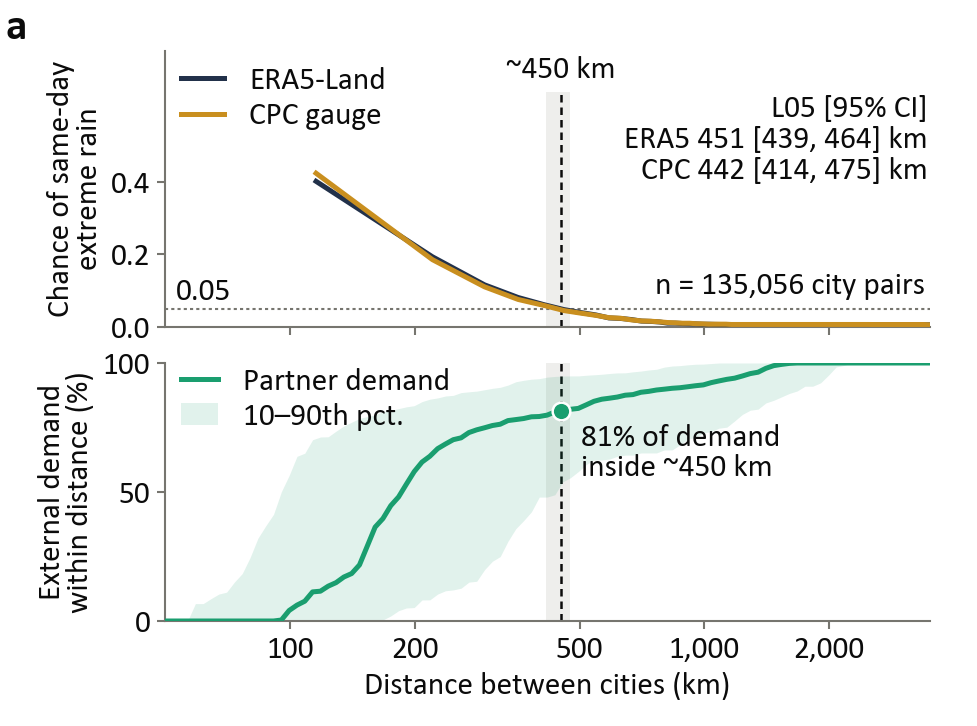

In [2]:
cur = pd.read_excel(BOOK, sheet_name="Fig2a_top")
L05 = pd.read_excel(BOOK, sheet_name="Fig2a_L05").set_index("product_code")
cdf = pd.read_excel(BOOK, sheet_name="Fig2a_bottom")
asum = pd.read_excel(BOOK, sheet_name="Fig2a_summary").set_index("item")["value"]

X0, Y0, PW, PH = 0.0, 1.84, 3.26, H - 1.84
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
letter(0.02, AT1 + LET, "a")
Lera = float(L05.loc["ERA5-EF", "L05_km"])
lo_ci, hi_ci = L05.L05_ci_low_km.min(), L05.L05_ci_high_km.max()
axa = ax_in(0.55, AT1 - 0.92, 2.55, 0.92)
axc2 = ax_in(0.55, AB1, 2.55, 0.86)
for ax_ in (axa, axc2):
    clean(ax_, grid=None)
    dist_axis(ax_, labels=ax_ is axc2)
    _top = 0.85 if ax_ is axa else 1.0
    ax_.axvspan(lo_ci, hi_ci, ymax=_top, color=GRIDC, lw=0, zorder=0)
    ax_.axvline(Lera, ymax=_top, **REF, zorder=1)
axa.axhline(0.05, color=INK3, lw=0.5, ls=(0, (1.5, 1.5)), zorder=1)
axa.text(53, 0.058, "0.05", fontsize=BASE, color=INK, ha="left", va="bottom")
for p, (lab, col) in PROD.items():
    cu = cur.loc[cur.product_code == p].sort_values("distance_km")
    axa.plot(cu.distance_km, cu.chance_same_day_extreme_rain, color=col, lw=1.2, zorder=3)
axa.text(Lera, 0.745, "~450 km", fontsize=BASE, color=INK, ha="center", va="top", zorder=6)
e5, c5 = L05.loc["ERA5-EF"], L05.loc["CPC-EF"]
axa.text(3450, 0.64, f"L05 [95% CI]\nERA5 {e5.L05_km:.0f} [{e5.L05_ci_low_km:.0f}, {e5.L05_ci_high_km:.0f}] km\n"
                     f"CPC {c5.L05_km:.0f} [{c5.L05_ci_low_km:.0f}, {c5.L05_ci_high_km:.0f}] km",
         fontsize=BASE, color=INK, ha="right", va="top", linespacing=1.15, zorder=6)
axa.legend(handles=[Line2D([], [], color=NAVY, lw=1.2, label="ERA5-Land"),
                    Line2D([], [], color=OCHRE, lw=1.2, label="CPC gauge")],
           loc="upper left", bbox_to_anchor=(0.0, 1.0), handlelength=1.4, labelspacing=0.25, borderaxespad=0.1)
axa.text(3400, 0.075, f"n = {int(e5.n_city_pairs):,} city pairs", fontsize=BASE, color=INK, ha="right", va="bottom")
axa.set_ylim(0, 0.76)
axa.set_yticks([0, 0.2, 0.4])
axa.set_ylabel("Chance of same-day\nextreme rain", linespacing=1.0)
share = float(asum["median share of partner demand inside the ERA5 L05 distance"])
axc2.fill_between(cdf.distance_km, 100 * cdf.p10_share, 100 * cdf.p90_share, color=DEMAND, alpha=0.13, lw=0, zorder=1)
axc2.plot(cdf.distance_km, 100 * cdf.median_share, color=DEMAND, lw=1.2, zorder=3)
axc2.scatter([Lera], [100 * share], s=18, color=DEMAND, edgecolor="white", lw=0.6, zorder=5)
axc2.text(Lera * 1.12, 100 * share - 5, f"{share:.0%} of demand\ninside ~450 km", fontsize=BASE,
          color=INK, ha="left", va="top", linespacing=1.1, zorder=6)
axc2.legend(handles=[Line2D([], [], color=DEMAND, lw=1.2, label="Partner demand"),
                     Patch(color=DEMAND, alpha=0.13, lw=0, label="10–90th pct.")],
            loc="upper left", bbox_to_anchor=(0.0, 1.04), handlelength=1.2, labelspacing=0.2, borderaxespad=0.1)
axc2.set_ylim(0, 100)
axc2.set_yticks([0, 50, 100])
axc2.set_xlabel("Distance between cities (km)")
axc2.set_ylabel("External demand\nwithin distance (%)", linespacing=1.0)
plt.show()

**Panel b**: share of external demand and of shared-rain exposure by distance band.

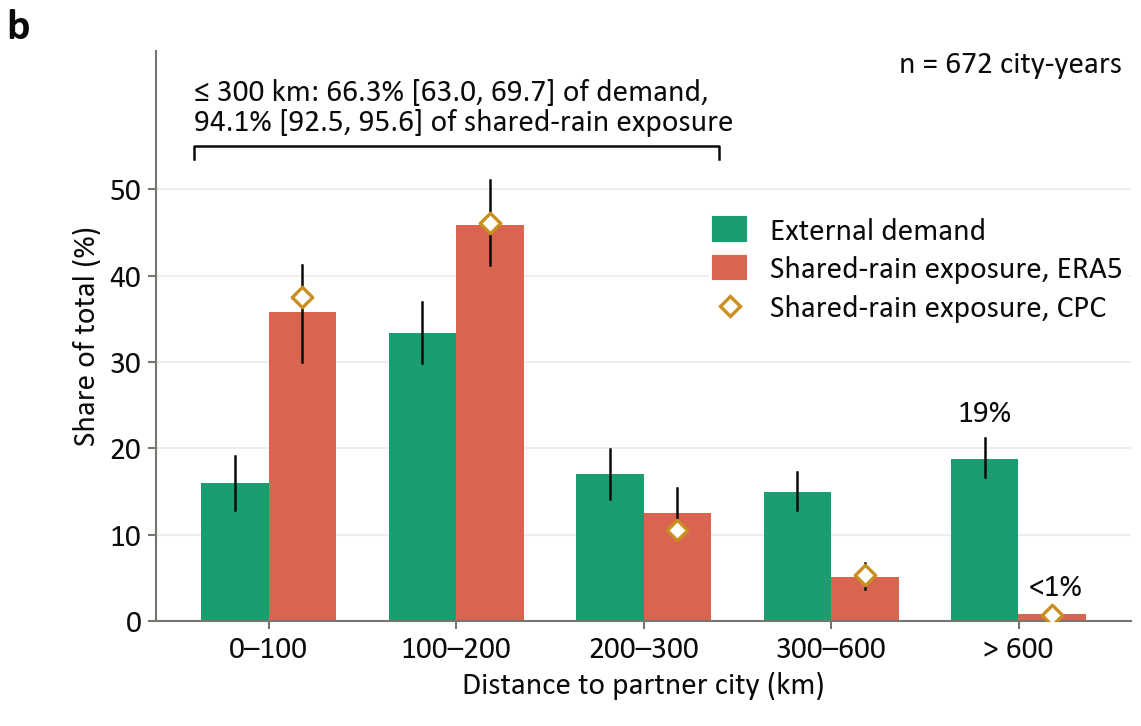

In [3]:
bands = pd.read_excel(BOOK, sheet_name="Fig2b")

X0, Y0, PW, PH = 3.28, 1.84, WIDTH - 3.28, H - 1.84
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
BANDS = ["0-100", "100-200", "200-300", "300-600", ">600"]
e3 = bands.loc[bands.product_code == "ERA5-EF"].set_index("band_km")
c3 = bands.loc[bands.product_code == "CPC-EF"].set_index("band_km")
cum = e3.loc["<=300 (cum)"]
BX = 3.80
letter(BX - 0.50, AT1 + LET, "b")
axb = ax_in(BX, AB1, 7.05 - BX, R1H)
clean(axb)
x = np.arange(len(BANDS))
bw = 0.36
for j, b in enumerate(BANDS):
    r = e3.loc[b]
    axb.bar(x[j] - bw / 2, 100 * r.demand_share, width=bw, color=DEMAND, lw=0, zorder=2)
    axb.bar(x[j] + bw / 2, 100 * r.exposure_share, width=bw, color=CORAL, lw=0, zorder=2)
    axb.plot([x[j] - bw / 2] * 2, [100 * r.demand_ci_low, 100 * r.demand_ci_high], color=INK, lw=0.6, zorder=3)
    axb.plot([x[j] + bw / 2] * 2, [100 * r.exposure_ci_low, 100 * r.exposure_ci_high], color=INK, lw=0.6, zorder=3)
    axb.scatter([x[j] + bw / 2], [100 * c3.loc[b].exposure_share], s=12, marker="D", facecolor="white",
                edgecolor=OCHRE, lw=0.8, zorder=4)
r6 = e3.loc[">600"]
axb.text(x[4] - bw / 2, 100 * r6.demand_ci_high + 1.2, f"{r6.demand_share:.0%}", fontsize=BASE, color=INK,
         ha="center", va="bottom")
axb.text(x[4] + bw / 2 + 0.02, 100 * r6.exposure_ci_high + 1.2,
         "<1%" if r6.exposure_share < 0.01 else f"{r6.exposure_share:.0%}", fontsize=BASE, color=INK, ha="center",
         va="bottom")
yb = 55.0
axb.plot([x[0] - 0.4, x[0] - 0.4, x[2] + 0.4, x[2] + 0.4], [yb - 1.5, yb, yb, yb - 1.5], color=INK, lw=0.6)
axb.text(x[0] - 0.4, yb + 1.0,
         f"≤ 300 km: {ci_txt(cum.demand_share, cum.demand_ci_low, cum.demand_ci_high, pct=True)} of demand,\n"
         f"{ci_txt(cum.exposure_share, cum.exposure_ci_low, cum.exposure_ci_high, pct=True)} of shared-rain exposure",
         fontsize=BASE, color=INK, ha="left", va="bottom", linespacing=1.1)
axb.set_xticks(x)
axb.set_xticklabels(["0–100", "100–200", "200–300", "300–600", "> 600"])
axb.set_xlim(-0.6, len(BANDS) - 0.4)
axb.set_ylim(0, 66)
axb.set_yticks([0, 10, 20, 30, 40, 50])
axb.set_xlabel("Distance to partner city (km)")
axb.set_ylabel("Share of total (%)")
axb.legend(handles=[Patch(color=DEMAND, label="External demand"),
                    Patch(color=CORAL, label="Shared-rain exposure, ERA5"),
                    Line2D([], [], ls="", marker="D", ms=3.5, mfc="white", mec=OCHRE, mew=0.8,
                           label="Shared-rain exposure, CPC")],
           loc="center right", bbox_to_anchor=(1.0, 0.615), handlelength=1.0, labelspacing=0.35, borderaxespad=0.1,
           frameon=True, borderpad=0.15)
axb.get_legend().get_frame().set(visible=True, facecolor="white", edgecolor="none", alpha=1.0)
axb.text(len(BANDS) - 0.45, 66, f"n = {int(cum.n_city_years)} city-years", fontsize=BASE, color=INK, ha="right",
         va="top")
plt.show()

**Panel c**: shared-rain share S of observed partners against random partners at the same distance and anywhere.

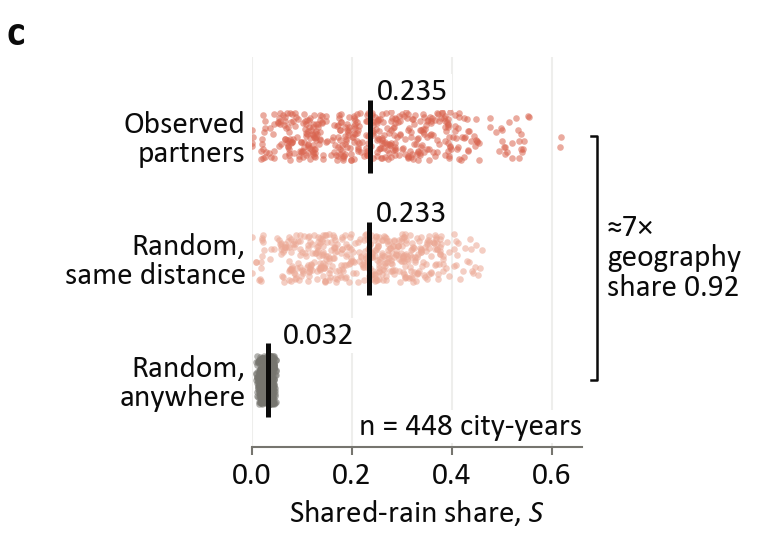

In [4]:
pts = pd.read_excel(BOOK, sheet_name="Fig2c")
csum = pd.read_excel(BOOK, sheet_name="Fig2c_summary").set_index("item")["value"]

X0, Y0, PW, PH = 0.0, 0.0, 2.60, 1.84
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
letter(0.02, AT2 + LET, "c")
axd = ax_in(0.84, AB2, 1.10, R2H)
clean(axd, grid="x")
rng = np.random.default_rng(7)                                  # vertical jitter of the points
DROWS = [("S_observed", "Observed\npartners", CORAL, "median S, observed partners"),
         ("S_random_same_distance", "Random,\nsame distance", "#eba793", "median S, random partners at the same distance"),
         ("S_random_anywhere", "Random,\nanywhere", INK3, "median S, random partners anywhere")]
for j, (c, lab, col, key) in enumerate(DROWS):
    v = pts[c].to_numpy()
    md = float(csum[key])
    axd.scatter(v, j + rng.uniform(-0.2, 0.2, v.size), s=2.5, color=col, alpha=0.55, lw=0, zorder=2)
    axd.plot([md] * 2, [j - 0.3, j + 0.3], color=INK, lw=1.2, zorder=3, solid_capstyle="butt")
    axd.text(md + (0.015 if c != "S_random_anywhere" else 0.03), j - 0.25, f"{md:.3f}", fontsize=BASE, color=INK,
             ha="left", va="bottom", zorder=4, bbox=dict(boxstyle="square,pad=0.12", facecolor="white", edgecolor="none"))
axd.set_ylim(2.55, -0.65)
axd.set_yticks([0, 1, 2])
axd.set_yticklabels([lab for _, lab, _, _ in DROWS], linespacing=1.05)
axd.tick_params(axis="y", length=0)
axd.spines["left"].set_visible(False)
axd.set_xlim(0, 0.66)
axd.set_xticks([0, 0.2, 0.4, 0.6])
axd.set_xlabel(r"Shared-rain share, $S$")
ratio = float(csum["ratio of medians, observed over random anywhere (ERA5)"])
geo = float(csum["geography share (median, ERA5)"])
xb = 0.69
axd.plot([xb - 0.012, xb, xb, xb - 0.012], [0, 0, 2, 2], color=INK, lw=0.6, clip_on=False)
axd.text(xb + 0.02, 1.0, f"≈{ratio:.0f}×\ngeography\nshare {geo:.2f}", fontsize=BASE, color=INK,
         ha="left", va="center", linespacing=1.1, clip_on=False)
axd.text(0.66, 2.5, f"n = {len(pts)} city-years", fontsize=BASE, color=INK, ha="right", va="bottom", zorder=4,
         bbox=dict(boxstyle="square,pad=0.08", facecolor="white", edgecolor="none"))
plt.show()

**Panel d**: effective and independent-equivalent numbers of origin cities across city-years.

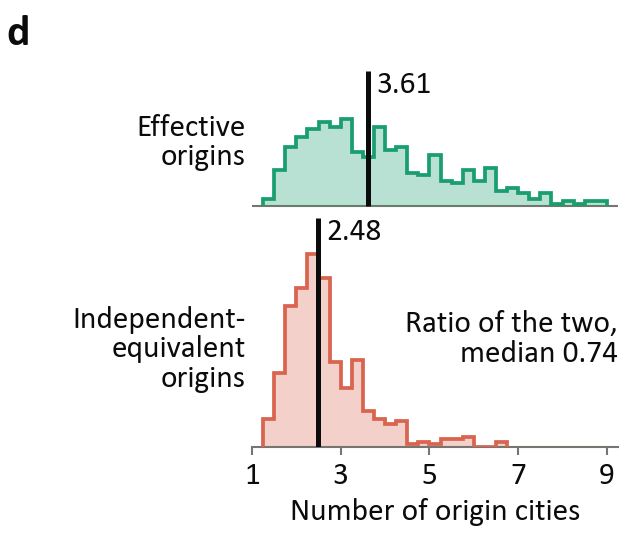

In [5]:
hist = pd.read_excel(BOOK, sheet_name="Fig2d")
dsum = pd.read_excel(BOOK, sheet_name="Fig2d_summary").set_index("item")["value"]

X0, Y0, PW, PH = 2.60, 0.0, 2.14, 1.84
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
letter(2.62, AT2 + LET, "d")
axh = ax_in(3.44, AB2, 1.22, R2H)
clean(axh, grid=None)
edges = np.r_[hist.bin_low.to_numpy(), hist.bin_high.to_numpy()[-1]]
counts = {"eff": hist.n_city_years_effective.to_numpy(), "ind": hist.n_city_years_independent_equivalent.to_numpy()}
HSC = 0.80 / max(h.max() for h in counts.values())              # common scale: tallest bin = 0.80 of a row
HROWS = [("eff", DEMAND, "Effective\norigins", float(dsum["median effective origins"]), 1.0),
         ("ind", CORAL, "Independent-\nequivalent\norigins", float(dsum["median independent-equivalent origins"]), 0.0)]
for c, col, lab, med, y0 in HROWS:
    nz = np.flatnonzero(counts[c])
    hs, he = counts[c][nz[0]:nz[-1] + 1] * HSC, edges[nz[0]:nz[-1] + 2]
    axh.stairs(hs + y0, he, baseline=y0, fill=True, color=col, alpha=0.30, lw=0, zorder=2)
    axh.stairs(hs + y0, he, baseline=y0, color=col, lw=0.9, zorder=3)
    if y0 > 0:
        axh.plot([1, 9.25], [y0, y0], color=INK3, lw=0.5, zorder=1)
    ytop = y0 + (0.95 if c == "ind" else 0.56)
    axh.plot([med, med], [y0, ytop], color=INK, lw=1.2, solid_capstyle="butt", zorder=4)
    axh.text(med + 0.2, ytop, f"{med:.2f}", fontsize=BASE, color=INK, ha="left", va="top", zorder=5)
ratio = float(dsum["median city-year ratio of independent-equivalent to effective origins"])
axh.text(9.25, 0.45, f"Ratio of the two,\nmedian {ratio:.2f}", fontsize=BASE, color=INK, ha="right", va="center",
         linespacing=1.1, zorder=5)
axh.set_xlim(1, 9.25)
axh.set_xticks([1, 3, 5, 7, 9])
axh.set_ylim(0, 1.62)
axh.set_yticks([0.42, 1.28])
axh.set_yticklabels([lab for _, _, lab, _, _ in HROWS][::-1], linespacing=1.05)
axh.tick_params(axis="y", length=0)
axh.spines["left"].set_visible(False)
axh.set_xlabel("Number of origin cities")
plt.show()

**Panel e**: change per s.d. more origin cities in the average share hit, its day-to-day spread and the chance that at least half is hit.

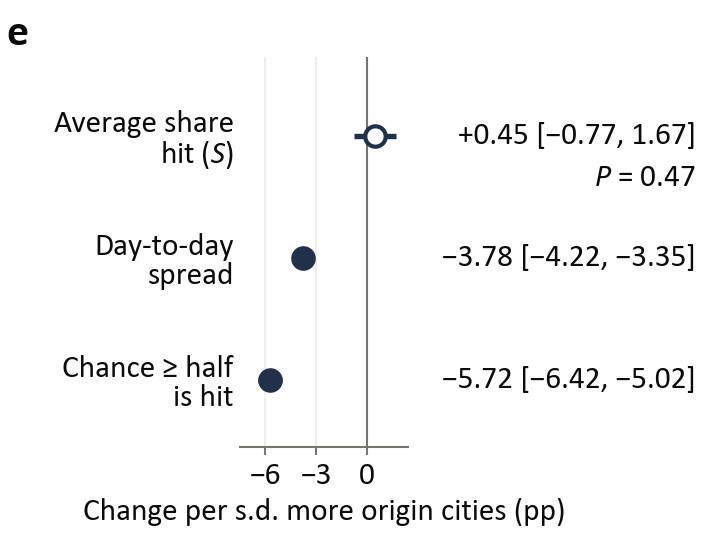

In [6]:
coef = pd.read_excel(BOOK, sheet_name="Fig2e")

X0, Y0, PW, PH = 4.74, 0.0, WIDTH - 4.74, 1.84
fig, ax_in, letter, T = panel_figure(X0, Y0, PW, PH)
letter(4.76, AT2 + LET, "e")
EVX = 7.06                                                      # right edge of the value column (in)
axe = ax_in(5.54, AB2, 0.56, R2H)
clean(axe, grid="x")
vt = blended_transform_factory(fig.transFigure, axe.transData)
E_LAB = {"a_mean": "Average share\nhit ($S$)", "b_sd": "Day-to-day\nspread", "b_tail": "Chance ≥ half\nis hit"}
for k, r in enumerate(coef.itertuples()):
    sig = r.p_value < 0.05
    axe.plot([r.ci_low_pp, r.ci_high_pp], [k, k], color=NAVY, lw=1.3, solid_capstyle="butt", zorder=2)
    axe.scatter([r.estimate_pp], [k], s=24, facecolor=NAVY if sig else "white", edgecolor=NAVY, lw=1.0, zorder=3)
    val = f"{mfmt(r.estimate_pp, 2)} [{mfmt(r.ci_low_pp, 2)}, {mfmt(r.ci_high_pp, 2)}]".replace("+", "")
    val = ("+" if r.estimate_pp > 0 else "") + val
    axe.text((EVX - X0) / PW, k, val, transform=vt, fontsize=BASE, color=INK, ha="right", va="center", clip_on=False)
axe.text((EVX - X0) / PW, 0.34, rf"$P$ = {coef.p_value.iloc[0]:.2f}", transform=vt, fontsize=BASE, color=INK,
         ha="right", va="center", clip_on=False)
axe.axvline(0, color=INK3, lw=0.5)
axe.set_xlim(-7.5, 2.4)
axe.set_xticks([-6, -3, 0])
axe.set_ylim(2.55, -0.65)
axe.set_yticks([0, 1, 2])
axe.set_yticklabels([E_LAB[t] for t in coef.test], linespacing=1.05)
axe.tick_params(axis="y", length=0)
axe.spines["left"].set_visible(False)
axe.set_xlabel("Change per s.d. more origin cities (pp)")
plt.show()